# MoTrPAC rat-heart data audit — Google Drive version

This notebook mounts Google Drive and saves the R script, installation log, analysis outputs, PCA, CSV files, RDS objects, and final ZIP in:

`My Drive/MoTrPAC_2day_hackathon/`


In [1]:
# Mount Google Drive and create the project folder
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/MoTrPAC_2day_hackathon')
DRIVE_PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print('All files will be saved in:')
print(DRIVE_PROJECT_DIR)


Mounted at /content/drive
All files will be saved in:
/content/drive/MyDrive/MoTrPAC_2day_hackathon


In [2]:
# Check the environment
import os, shutil, subprocess, sys
print('Python:', sys.version)
print('R before installation:', shutil.which('R'))
!cat /etc/os-release | head


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
R before installation: /usr/local/bin/R
PRETTY_NAME="Ubuntu 22.04.5 LTS"
NAME="Ubuntu"
VERSION_ID="22.04"
VERSION="22.04.5 LTS (Jammy Jellyfish)"
VERSION_CODENAME=jammy
ID=ubuntu
ID_LIKE=debian
HOME_URL="https://www.ubuntu.com/"
SUPPORT_URL="https://help.ubuntu.com/"
BUG_REPORT_URL="https://bugs.launchpad.net/ubuntu/"


In [3]:
# Install R and required system libraries if needed
import shutil, subprocess

if shutil.which('R') is None:
    subprocess.run(['apt-get', 'update', '-qq'], check=True)
    subprocess.run([
        'apt-get', 'install', '-y',
        'r-base', 'r-base-dev', 'git', 'build-essential',
        'libcurl4-openssl-dev', 'libssl-dev', 'libxml2-dev',
        'libfontconfig1-dev', 'libharfbuzz-dev', 'libfribidi-dev',
        'libfreetype6-dev', 'libpng-dev', 'libtiff5-dev', 'libjpeg-dev'
    ], check=True)

!R --version


R version 4.6.0 (2026-04-24) -- "Because it was There"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: x86_64-pc-linux-gnu

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under the terms of the
GNU General Public License versions 2 or 3.
For more information about these matters see
https://www.gnu.org/licenses/.



## Write the lightweight R audit script

No ZIP upload is needed for this notebook.

In [4]:
from pathlib import Path
r_code = r'''
# ============================================================
# MoTrPAC 2-Day Hackathon
# Step 1: Rat heart transcriptomics data audit and PCA
# Lightweight Colab version: data package only
# Author: Upama
# ============================================================

options(timeout = 1e5)
options(repos = c(CRAN = "https://cloud.r-project.org"))

message("R version: ", R.version.string)
message("Working directory: ", getwd())

# -----------------------------
# 1. Install only what is needed
# -----------------------------
cran_packages <- c("remotes", "dplyr", "ggplot2", "readr", "tibble")

missing_cran <- cran_packages[
  !vapply(cran_packages, requireNamespace, logical(1), quietly = TRUE)
]

if (length(missing_cran) > 0) {
  message("Installing CRAN packages: ", paste(missing_cran, collapse = ", "))
  install.packages(missing_cran, Ncpus = 2)
}

# IMPORTANT:
# Install ONLY the official data package.
# dependencies = FALSE prevents installation of its large optional Suggests list.
if (!requireNamespace("MotrpacRatTraining6moData", quietly = TRUE)) {
  message("Installing MotrpacRatTraining6moData from GitHub...")
  remotes::install_github(
    "MoTrPAC/MotrpacRatTraining6moData",
    upgrade = "never",
    dependencies = FALSE,
    build_vignettes = FALSE,
    force = TRUE
  )
}

# -----------------------------
# 2. Load libraries and objects
# -----------------------------
suppressPackageStartupMessages({
  library(MotrpacRatTraining6moData)
  library(dplyr)
  library(ggplot2)
  library(readr)
  library(tibble)
})

message(
  "Loaded MotrpacRatTraining6moData version ",
  as.character(packageVersion("MotrpacRatTraining6moData"))
)

data("PHENO", package = "MotrpacRatTraining6moData")
data("OUTLIERS", package = "MotrpacRatTraining6moData")
data("TRNSCRPT_HEART_RAW_COUNTS", package = "MotrpacRatTraining6moData")
data("TRNSCRPT_HEART_NORM_DATA", package = "MotrpacRatTraining6moData")

rna_raw <- TRNSCRPT_HEART_RAW_COUNTS
rna_norm <- TRNSCRPT_HEART_NORM_DATA

# -----------------------------
# 3. Output directory
# -----------------------------
output_dir <- file.path("results", "01_rat_heart_data_audit")
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

# -----------------------------
# 4. Detect sample columns
# Official sample-level objects have four metadata columns first.
# Also verify IDs against PHENO rather than relying only on position.
# -----------------------------
pheno_ids <- unique(c(
  rownames(PHENO),
  if ("viallabel" %in% colnames(PHENO)) as.character(PHENO$viallabel) else character()
))

raw_candidates <- colnames(rna_raw)[-(1:min(4, ncol(rna_raw)))]
norm_candidates <- colnames(rna_norm)[-(1:min(4, ncol(rna_norm)))]

raw_sample_ids <- intersect(raw_candidates, pheno_ids)
norm_sample_ids <- intersect(norm_candidates, pheno_ids)

if (length(raw_sample_ids) == 0 || length(norm_sample_ids) == 0) {
  stop(
    "No RNA-seq sample columns matched PHENO identifiers.\\n",
    "Raw columns: ", paste(head(colnames(rna_raw), 10), collapse = ", "), "\\n",
    "Normalized columns: ", paste(head(colnames(rna_norm), 10), collapse = ", ")
  )
}

# -----------------------------
# 5. Match phenotype metadata
# -----------------------------
get_pheno_rows <- function(sample_ids, pheno) {
  if (all(sample_ids %in% rownames(pheno))) {
    ans <- pheno[sample_ids, , drop = FALSE]
    ans$viallabel_from_matrix <- rownames(ans)
    return(ans)
  }

  if ("viallabel" %in% colnames(pheno)) {
    idx <- match(sample_ids, as.character(pheno$viallabel))
    if (anyNA(idx)) {
      stop(
        "Could not match these sample IDs to PHENO$viallabel: ",
        paste(sample_ids[is.na(idx)], collapse = ", ")
      )
    }
    ans <- pheno[idx, , drop = FALSE]
    ans$viallabel_from_matrix <- sample_ids
    rownames(ans) <- sample_ids
    return(ans)
  }

  stop("PHENO has neither matching row names nor a viallabel column.")
}

sample_metadata_full <- get_pheno_rows(norm_sample_ids, PHENO)

keep_metadata_columns <- intersect(
  c(
    "viallabel_from_matrix", "viallabel", "pid", "bid",
    "sex", "group", "intervention", "sacrificetime",
    "study_group_timepoint",
    "specimen_processing___sampletypedescription",
    "registration___sex",
    "time_to_freeze",
    "vo2.max.test.vo2_max",
    "calculated.variables.vo2_max_change",
    "calculated.variables.pct_body_fat_change",
    "calculated.variables.pct_body_lean_change",
    "terminal.weight.bw"
  ),
  colnames(sample_metadata_full)
)

sample_metadata <- sample_metadata_full[, keep_metadata_columns, drop = FALSE]

# Ensure a single vial-label column is available.
if (!"viallabel" %in% colnames(sample_metadata)) {
  sample_metadata$viallabel <- sample_metadata$viallabel_from_matrix
}
sample_metadata$viallabel <- as.character(sample_metadata$viallabel)

# -----------------------------
# 6. Official heart RNA-seq outliers
# -----------------------------
heart_rna_outliers <- OUTLIERS |>
  filter(tissue == "HEART", assay == "TRNSCRPT") |>
  mutate(viallabel = as.character(viallabel))

sample_metadata <- sample_metadata |>
  mutate(
    official_outlier = viallabel %in% heart_rna_outliers$viallabel
  )

if (all(c("sex", "group") %in% colnames(sample_metadata))) {
  sample_metadata <- sample_metadata |>
    mutate(
      analysis_group = factor(
        paste(sex, group, sep = "_"),
        levels = c(
          "female_control", "female_1w", "female_2w",
          "female_4w", "female_8w",
          "male_control", "male_1w", "male_2w",
          "male_4w", "male_8w"
        )
      )
    )
}

norm_no_outlier_ids <- setdiff(
  norm_sample_ids,
  heart_rna_outliers$viallabel
)

# -----------------------------
# 7. Audit summaries
# -----------------------------
feature_columns_raw <- setdiff(colnames(rna_raw), raw_sample_ids)
feature_columns_norm <- setdiff(colnames(rna_norm), norm_sample_ids)

inventory <- tibble(
  item = c(
    "Raw RNA-seq feature rows",
    "Raw RNA-seq sample columns",
    "Normalized RNA-seq feature rows",
    "Normalized RNA-seq sample columns",
    "Normalized samples after official outlier removal",
    "Official heart RNA-seq outliers",
    "Installed data-package version"
  ),
  value = c(
    as.character(nrow(rna_raw)),
    as.character(length(raw_sample_ids)),
    as.character(nrow(rna_norm)),
    as.character(length(norm_sample_ids)),
    as.character(length(norm_no_outlier_ids)),
    as.character(nrow(heart_rna_outliers)),
    as.character(packageVersion("MotrpacRatTraining6moData"))
  )
)

if (all(c("sex", "group") %in% colnames(sample_metadata))) {
  group_counts <- sample_metadata |>
    count(sex, group, official_outlier, name = "n") |>
    arrange(
      sex,
      factor(group, levels = c("control", "1w", "2w", "4w", "8w"))
    )
} else {
  group_counts <- tibble(
    warning = "sex and/or group column was not found in PHENO"
  )
}

sample_matching_check <- tibble(
  check = c(
    "Raw and normalized sample sets identical",
    "All normalized samples matched to PHENO",
    "All non-outlier samples are in full normalized data",
    "All sex values present",
    "All group values present"
  ),
  passed = c(
    setequal(raw_sample_ids, norm_sample_ids),
    all(norm_sample_ids %in% sample_metadata$viallabel),
    all(norm_no_outlier_ids %in% norm_sample_ids),
    if ("sex" %in% colnames(sample_metadata)) {
      all(!is.na(sample_metadata$sex))
    } else {
      FALSE
    },
    if ("group" %in% colnames(sample_metadata)) {
      all(!is.na(sample_metadata$group))
    } else {
      FALSE
    }
  )
)

# -----------------------------
# 8. PCA
# -----------------------------
pca_sample_ids <- norm_no_outlier_ids

pca_matrix <- as.matrix(
  rna_norm[, pca_sample_ids, drop = FALSE]
)
storage.mode(pca_matrix) <- "numeric"

keep_for_pca <- apply(
  pca_matrix,
  1,
  function(x) all(is.finite(x)) && !is.na(stats::sd(x)) && stats::sd(x) > 0
)
pca_matrix <- pca_matrix[keep_for_pca, , drop = FALSE]

# Use the 5,000 most variable genes for a quick, stable QC PCA.
gene_variance <- apply(pca_matrix, 1, stats::var)
top_n <- min(5000L, length(gene_variance))
top_idx <- order(gene_variance, decreasing = TRUE)[seq_len(top_n)]
pca_matrix <- pca_matrix[top_idx, , drop = FALSE]

if (nrow(pca_matrix) < 2 || ncol(pca_matrix) < 3) {
  stop("Too little usable data remained for PCA.")
}

pca_fit <- prcomp(
  t(pca_matrix),
  center = TRUE,
  scale. = FALSE
)

percent_variance <- 100 * pca_fit$sdev^2 / sum(pca_fit$sdev^2)

pca_metadata <- sample_metadata[
  match(pca_sample_ids, sample_metadata$viallabel),
  ,
  drop = FALSE
]

pca_table <- as.data.frame(pca_fit$x[, 1:3, drop = FALSE]) |>
  rownames_to_column("viallabel") |>
  left_join(pca_metadata, by = "viallabel")

if (!all(c("sex", "group") %in% colnames(pca_table))) {
  stop("PCA was computed, but PHENO did not provide sex and group columns.")
}

pca_plot <- ggplot(
  pca_table,
  aes(x = PC1, y = PC2, colour = sex, shape = group)
) +
  geom_point(size = 3.2, alpha = 0.9) +
  labs(
    title = "MoTrPAC rat heart transcriptomics PCA",
    subtitle = "Top 5,000 variable normalized genes; official RNA-seq outliers excluded",
    x = sprintf("PC1 (%.1f%%)", percent_variance[1]),
    y = sprintf("PC2 (%.1f%%)", percent_variance[2]),
    colour = "Sex",
    shape = "Training group"
  ) +
  theme_bw(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold"),
    legend.position = "right"
  )

# -----------------------------
# 9. Save outputs
# -----------------------------
write_csv(inventory, file.path(output_dir, "dataset_inventory.csv"))
write_csv(group_counts, file.path(output_dir, "sample_counts_by_group.csv"))
write_csv(sample_matching_check, file.path(output_dir, "sample_matching_checks.csv"))
write_csv(sample_metadata, file.path(output_dir, "heart_rnaseq_sample_metadata.csv"))
write_csv(heart_rna_outliers, file.path(output_dir, "official_heart_rnaseq_outliers.csv"))
write_csv(pca_table, file.path(output_dir, "heart_rnaseq_pca_coordinates.csv"))

write_csv(
  tibble(feature_metadata_column = feature_columns_raw),
  file.path(output_dir, "raw_count_feature_metadata_columns.csv")
)

write_csv(
  tibble(feature_metadata_column = feature_columns_norm),
  file.path(output_dir, "normalized_feature_metadata_columns.csv")
)

ggsave(
  filename = file.path(output_dir, "heart_rnaseq_pca.png"),
  plot = pca_plot,
  width = 8,
  height = 6,
  dpi = 300
)

saveRDS(
  list(
    rna_raw = rna_raw,
    rna_norm = rna_norm,
    sample_metadata = sample_metadata,
    heart_rna_outliers = heart_rna_outliers,
    pca_fit = pca_fit,
    pca_table = pca_table
  ),
  file.path(output_dir, "rat_heart_transcriptomics_audit_objects.rds"),
  compress = "xz"
)

capture.output(
  sessionInfo(),
  file = file.path(output_dir, "sessionInfo.txt")
)

cat("\\n================ DATASET INVENTORY ================\\n")
print(inventory)

cat("\\n================ SAMPLE COUNTS ====================\\n")
print(group_counts)

cat("\\n================ MATCHING CHECKS ==================\\n")
print(sample_matching_check)

cat("\\n================ OFFICIAL OUTLIERS ================\\n")
if (nrow(heart_rna_outliers) == 0) {
  cat("No official HEART/TRNSCRPT outliers were listed.\\n")
} else {
  print(heart_rna_outliers)
}

cat("\\nSUCCESS: PCA and audit files were saved to:\\n")
cat(normalizePath(output_dir, winslash = "/", mustWork = FALSE), "\\n")

'''
project_dir = Path('/content/drive/MyDrive/MoTrPAC_2day_hackathon')
project_dir.mkdir(parents=True, exist_ok=True)
script_path = project_dir / '01_rat_heart_data_audit_colab_fixed.R'
script_path.write_text(r_code, encoding='utf-8')
print('Wrote:', script_path)
print('Size:', script_path.stat().st_size, 'bytes')


Wrote: /content/drive/MyDrive/MoTrPAC_2day_hackathon/01_rat_heart_data_audit_colab_fixed.R
Size: 11357 bytes


## Run the R analysis and preserve the complete log

The data-package installation may pause for several minutes at `moving datasets to lazyload DB`. Do not interrupt it.

In [5]:
import subprocess
from pathlib import Path

project_dir = Path('/content/drive/MyDrive/MoTrPAC_2day_hackathon')
log_path = project_dir / 'r_analysis_full.log'

process = subprocess.Popen(
    ['Rscript', '--vanilla', '01_rat_heart_data_audit_colab_fixed.R'],
    cwd=str(project_dir),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

with log_path.open('w', encoding='utf-8') as log_file:
    for line in process.stdout:
        print(line, end='')
        log_file.write(line)

return_code = process.wait()
print('\nR return code:', return_code)
print('Full log:', log_path)

if return_code != 0:
    tail = log_path.read_text(encoding='utf-8', errors='replace').splitlines()[-120:]
    print('\n===== LAST 120 LOG LINES =====')
    print('\n'.join(tail))
    raise RuntimeError('R analysis failed. Upload r_analysis_full.log or copy the last error lines.')

print('Analysis completed successfully.')


R version: R version 4.6.0 (2026-04-24)
Working directory: /content/drive/MyDrive/MoTrPAC_2day_hackathon
Installing CRAN packages: remotes
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/remotes_2.5.0.tar.gz'
Content type 'application/x-gzip' length 164496 bytes (160 KB)
downloaded 160 KB

* installing *source* package ‘remotes’ ...
** this is package ‘remotes’ version ‘2.5.0’
** package ‘remotes’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (remotes)

The downloaded source packages are in
	‘/tmp/RtmpP43OxT

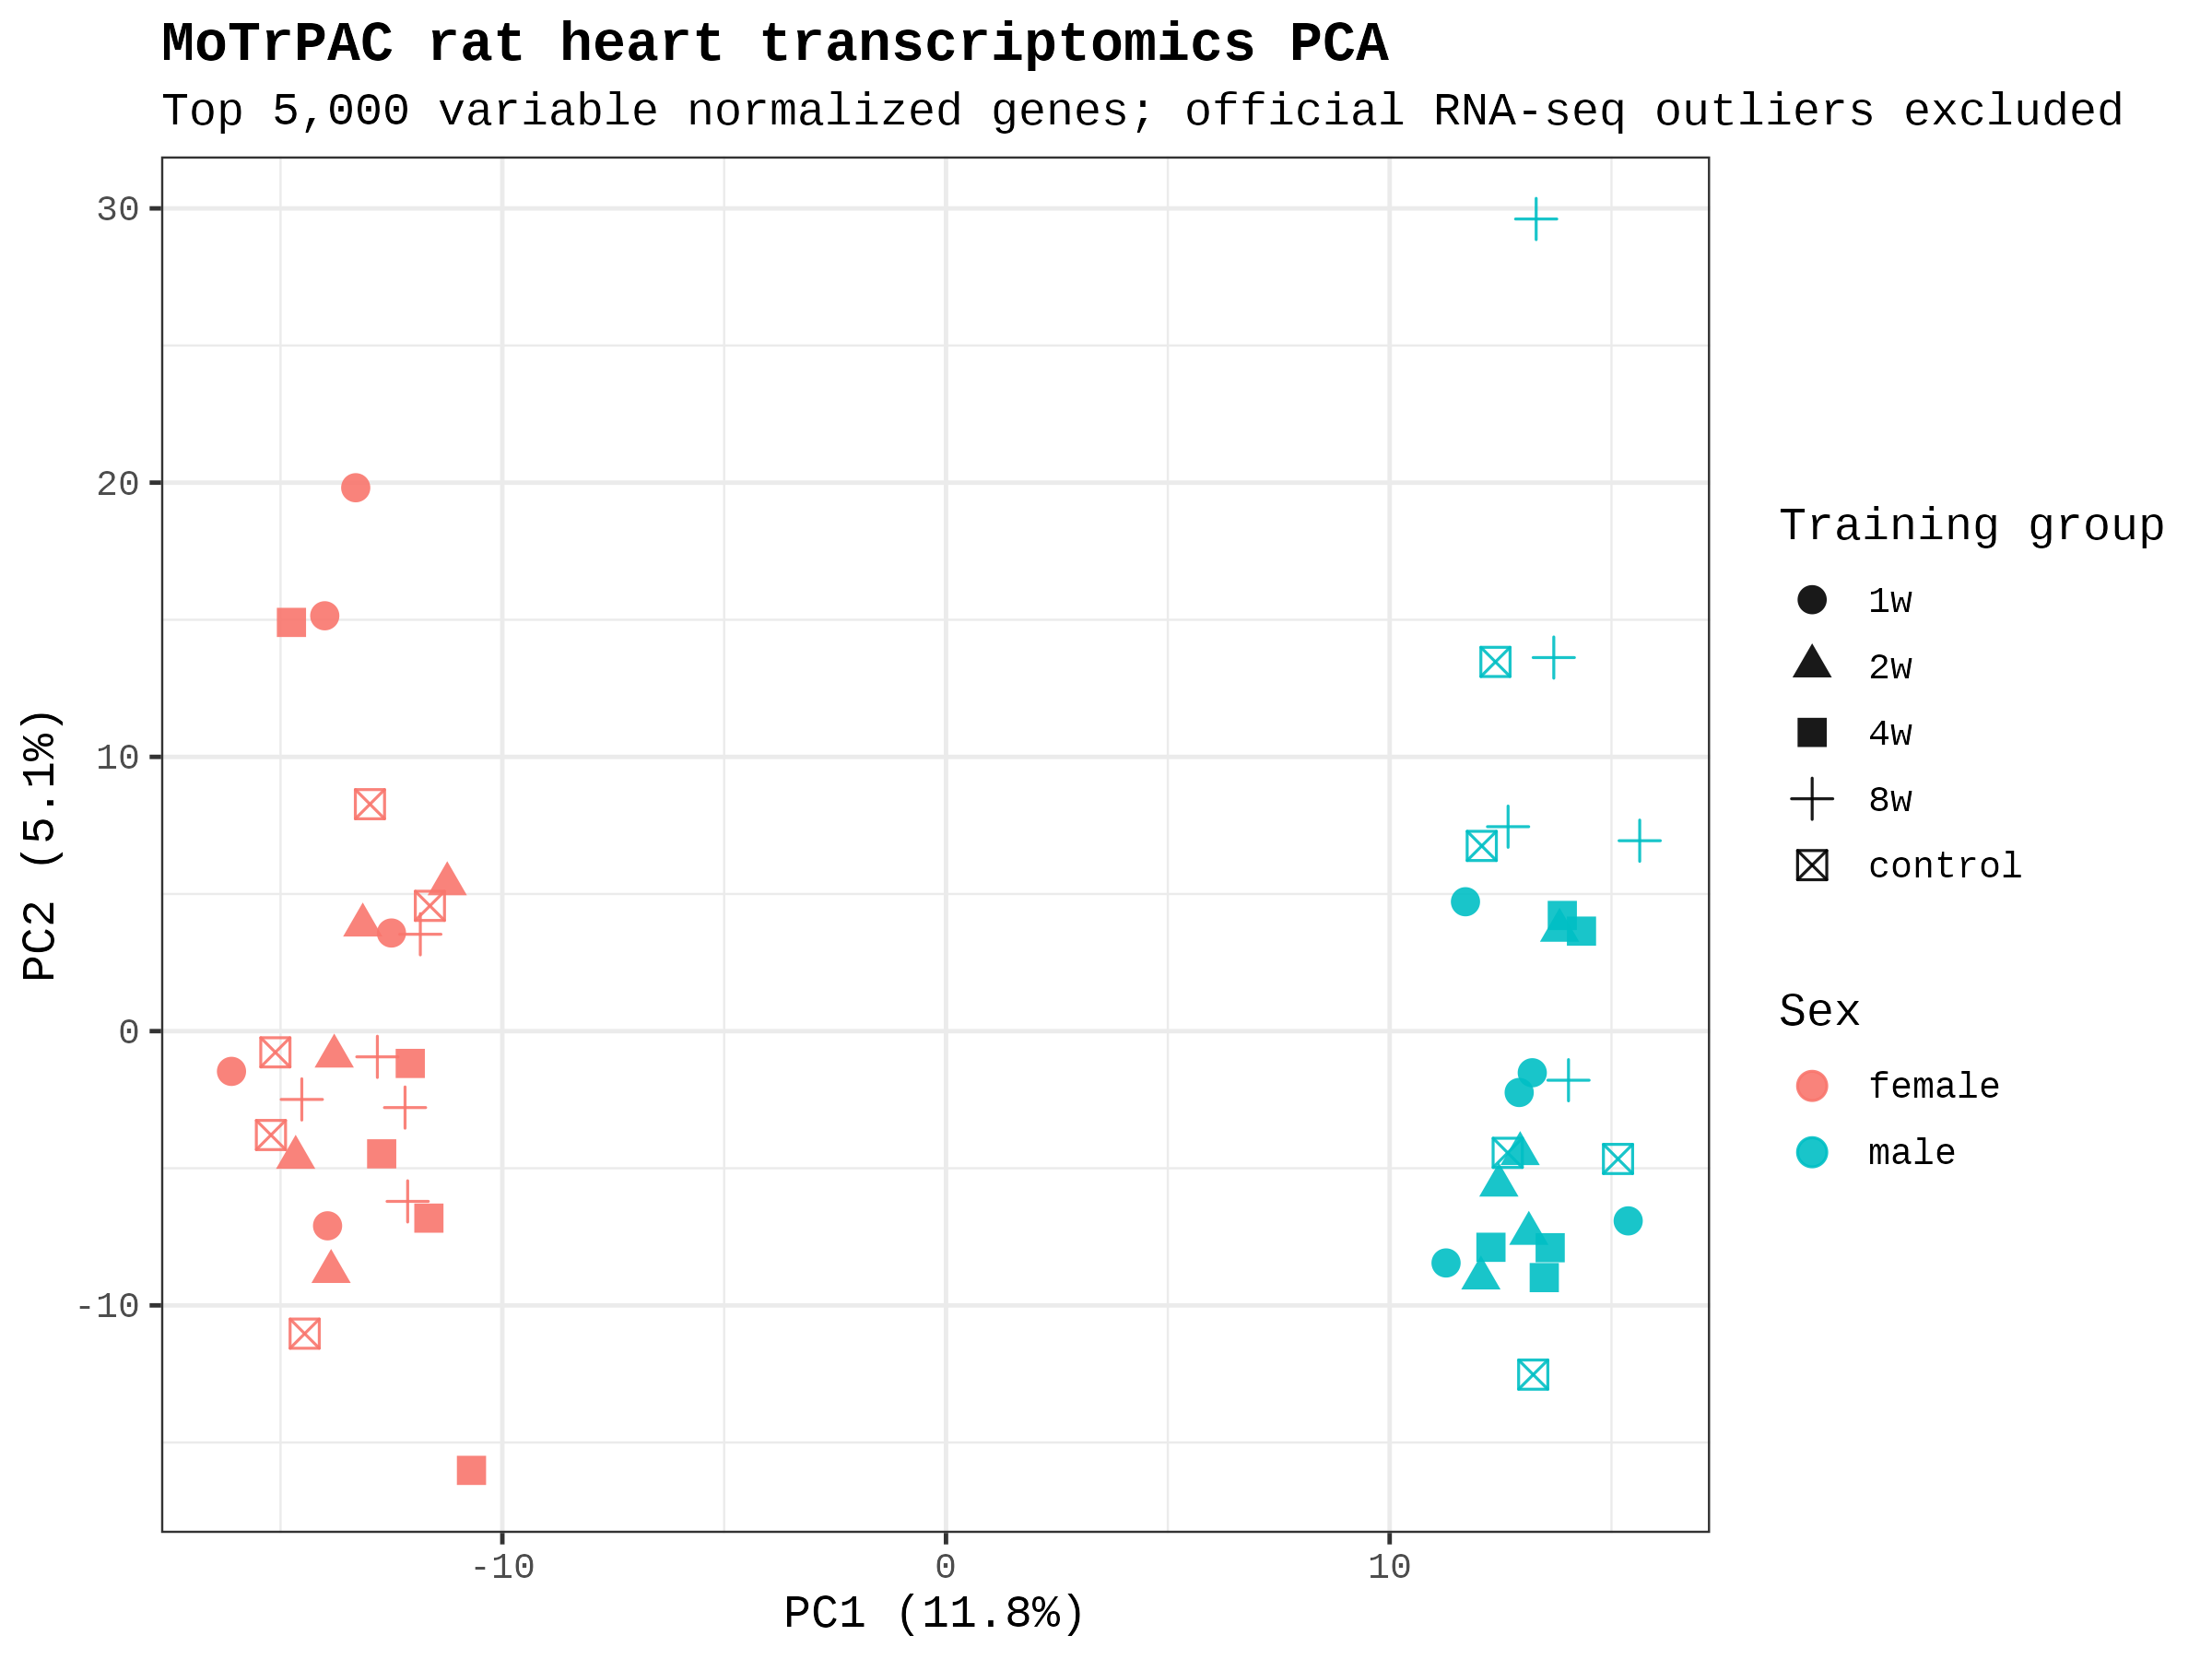


### dataset_inventory.csv


,item,value
0,Raw RNA-seq feature rows,32883
1,Raw RNA-seq sample columns,50
2,Normalized RNA-seq feature rows,14445
3,Normalized RNA-seq sample columns,50
4,Normalized samples after official outlier removal,50
5,Official heart RNA-seq outliers,0
6,Installed data-package version,2.0.0



### sample_counts_by_group.csv


,sex,group,official_outlier,n
0,female,control,False,5
1,female,1w,False,5
2,female,2w,False,5
3,female,4w,False,5
4,female,8w,False,5
5,male,control,False,5
6,male,1w,False,5
7,male,2w,False,5
8,male,4w,False,5
9,male,8w,False,5



### sample_matching_checks.csv


,check,passed
0,Raw and normalized sample sets identical,True
1,All normalized samples matched to PHENO,True
2,All non-outlier samples are in full normalized...,True
3,All sex values present,True
4,All group values present,True



### official_heart_rnaseq_outliers.csv


,viallabel,tissue,tissue_code,assay,assay_code,platform,pid,group,reason


In [8]:
from IPython.display import Image, display
import pandas as pd
from pathlib import Path

# Correct the path to point to the Google Drive project directory
project_dir = Path('/content/drive/MyDrive/MoTrPAC_2day_hackathon')
results_dir = project_dir / 'results' / '01_rat_heart_data_audit'

display(Image(filename=str(results_dir / 'heart_rnaseq_pca.png')))

for filename in [
    'dataset_inventory.csv',
    'sample_counts_by_group.csv',
    'sample_matching_checks.csv',
    'official_heart_rnaseq_outliers.csv'
]:
    print(f'\n### {filename}')
    display(pd.read_csv(results_dir / filename))


In [9]:
# Package the results and keep the ZIP in Google Drive
import shutil
from pathlib import Path

project_dir = Path('/content/drive/MyDrive/MoTrPAC_2day_hackathon')
results_dir = project_dir / 'results' / '01_rat_heart_data_audit'
archive_base = project_dir / 'rat_heart_data_audit_results'

archive_path = shutil.make_archive(
    str(archive_base),
    'zip',
    root_dir=str(results_dir)
)

print('Results ZIP saved to Google Drive:')
print(archive_path)

print('\nFiles currently saved in the project folder:')
for path in sorted(project_dir.rglob('*')):
    if path.is_file():
        print(path.relative_to(project_dir))


Results ZIP saved to Google Drive:
/content/drive/MyDrive/MoTrPAC_2day_hackathon/rat_heart_data_audit_results.zip

Files currently saved in the project folder:
01_rat_heart_data_audit_colab_fixed.R
r_analysis_full.log
rat_heart_data_audit_results.zip
results/01_rat_heart_data_audit/dataset_inventory.csv
results/01_rat_heart_data_audit/heart_rnaseq_pca.png
results/01_rat_heart_data_audit/heart_rnaseq_pca_coordinates.csv
results/01_rat_heart_data_audit/heart_rnaseq_sample_metadata.csv
results/01_rat_heart_data_audit/normalized_feature_metadata_columns.csv
results/01_rat_heart_data_audit/official_heart_rnaseq_outliers.csv
results/01_rat_heart_data_audit/rat_heart_transcriptomics_audit_objects.rds
results/01_rat_heart_data_audit/raw_count_feature_metadata_columns.csv
results/01_rat_heart_data_audit/sample_counts_by_group.csv
results/01_rat_heart_data_audit/sample_matching_checks.csv
results/01_rat_heart_data_audit/sessionInfo.txt


## Save the notebook itself

To keep the notebook in Google Drive too, select **File → Save a copy in Drive** in Colab.

Step 2: Differential-expression analysis